# FM · Які теплові точки з двох супутників це одна пожежа?

**Тип:** виміряно. **Навіщо:** Одна пожежа дає сотні теплових точок від двох сенсорів. Щоб рахувати пожежі, а не точки, їх треба звести в події.

Цей ноутбук повторює блок сторінки досліджень `web/science/#fm` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('FM'))

T13 · Крос-джерельний матчинг на реальних даних: VIIRS + MODIS проти офіційних периметрів EFFIS.

Задача      матчинг сигналів працює на моковому потоці, тож його якість звідти не виміряти. Тут той самий алгоритм групує реальні сигнали двох
            незалежних супутникових сенсорів про пожежі, а правильну відповідь дає незалежний третій джерело — картографовані EFFIS згарища.
Дані        NASA FIRMS, Греція, 2021–2025: VIIRS S-NPP (n, h) і MODIS (≥ 30). Еталон: EFFIS Burnt Areas, COUNTRY = EL.
            Сигнал належить згарищу, якщо лежить у його полігоні + 500 м і в датах [початок − 2 дні; кінець + 2 дні]. Оцінюються сигнали, що мають еталон.
Протокол    вибір параметрів — 2021–2023, тест — 2024–2025. 95 % CI — bootstrap по згарищах.
Метрики     BCubed F1 — основна: кластеризація оцінюється по кожному сигналу, великі пожежі не домінують. ARI — допоміжна.
            merge_rate — частка згарищ, які бачили обидва сенсори, що зведені в одну подію (сама суть крос-джерельного матчингу)

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_bcubed_f1,bcubed_f1,bcubed_f1_ci_lo,bcubed_f1_ci_hi,bcubed_f1_strict,champion,diff_base
0,day_5.0km,0.538,0.718,0.688,0.761,0.713,False,NaN
1,singleton,0.041,0.106,0.074,0.156,0.084,False,NaN
2,st_2.0km_5d,0.992,0.990,0.983,0.997,0.996,True,0.884
3,day_1.0km,0.489,0.641,0.601,0.695,0.645,False,NaN


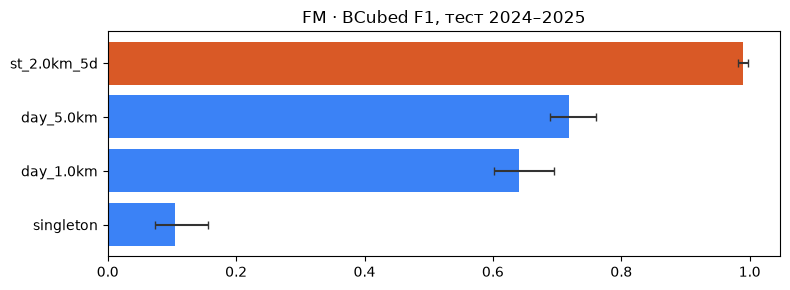

In [3]:
table, fig = report.show('FM')
table